# Sales Forecasting & Business Intelligence Platform

## Data Cleaning

This notebook applies the reusable preprocessing pipeline
to the UCI Online Retail II dataset.

The objective is to produce:

- Clean transaction data
- Valid sales
- Returns and cancellations
- Invalid transaction audit data
- Continuous daily revenue time series

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from ml.data.loader import (
    load_retail_data,
)

from ml.data.preprocessing import (
    preprocess_retail_data,
    save_processed_data,
)

In [3]:
# load data
raw_df = load_retail_data()

print(
    "Raw shape:",
    raw_df.shape,
)

raw_df.head()

Raw shape: (1067371, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


In [4]:
# run pipeline
result = preprocess_retail_data(
    raw_df
)

Duplicate rows removed: 12,133


In [5]:
# Clean Dataset
clean_df = (
    result.clean_data
)

clean_df.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet,is_cancelled,is_return,has_zero_quantity,has_negative_quantity,has_zero_price,has_negative_price,has_customer_id,line_revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,30.0


In [6]:
# shape
print(
    "Clean rows:",
    f"{len(clean_df):,}",
)

Clean rows: 1,055,238


In [7]:
# Valid Sales
valid_sales = (
    result.valid_sales
)

print(
    "Valid sales:",
    f"{len(valid_sales):,}",
)

valid_sales.head()

Valid sales: 1,029,609


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet,is_cancelled,is_return,has_zero_quantity,has_negative_quantity,has_zero_price,has_negative_price,has_customer_id,line_revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,False,False,False,False,False,True,30.0


In [8]:
# Returns / Cancellations
returns_df = (
    result.returns
)

print(
    "Returns / cancellations:",
    f"{len(returns_df):,}",
)

returns_df.head()

Returns / cancellations: 19,433


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet,is_cancelled,is_return,has_zero_quantity,has_negative_quantity,has_zero_price,has_negative_price,has_customer_id,line_revenue,return_revenue
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,Year 2009-2010,True,True,False,True,False,False,True,-35.4,-35.4
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,Year 2009-2010,True,True,False,True,False,False,True,-9.9,-9.9
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,Year 2009-2010,True,True,False,True,False,False,True,-17.0,-17.0
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,Year 2009-2010,True,True,False,True,False,False,True,-12.6,-12.6
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,Year 2009-2010,True,True,False,True,False,False,True,-35.4,-35.4


In [9]:
# Invalid Transactions
invalid_df = (
    result.invalid_transactions
)

print(
    "Invalid transactions:",
    f"{len(invalid_df):,}",
)

invalid_df.head()

Invalid transactions: 6,196


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet,is_cancelled,is_return,has_zero_quantity,has_negative_quantity,has_zero_price,has_negative_price,has_customer_id,line_revenue
0,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,Year 2009-2010,False,True,False,True,True,False,False,-0.0
1,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,Year 2009-2010,False,True,False,True,True,False,False,-0.0
2,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,Year 2009-2010,False,True,False,True,True,False,False,-0.0
3,489521,21646,UNKNOWN_PRODUCT,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,Year 2009-2010,False,True,False,True,True,False,False,-0.0
4,489655,20683,UNKNOWN_PRODUCT,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,Year 2009-2010,False,True,False,True,True,False,False,-0.0


In [10]:
# Daily Revenue
daily_revenue = (
    result.daily_revenue
)

daily_revenue.head(10)

,date,gross_revenue,transaction_lines,invoices,return_revenue,return_lines,net_revenue,return_rate,year,month,day_of_week,is_weekend
0,2009-12-01,54351.23,3068.0,119.0,-1340.47,110.0,53010.76,0.024663,2009,12,1,0
1,2009-12-02,63172.58,3208.0,115.0,-588.92,20.0,62583.66,0.009322,2009,12,2,0
2,2009-12-03,73972.45,2931.0,124.0,-5944.86,44.0,68027.59,0.080366,2009,12,3,0
3,2009-12-04,40582.32,2479.0,89.0,-386.52,27.0,40195.80,0.009524,2009,12,4,0
4,2009-12-05,9803.05,400.0,30.0,0.00,0.0,9803.05,0.000000,2009,12,5,1
5,2009-12-06,24423.02,1873.0,74.0,-296.44,31.0,24126.58,0.012138,2009,12,6,1
6,2009-12-07,44916.21,2804.0,101.0,-746.33,36.0,44169.88,0.016616,2009,12,0,0
7,2009-12-08,49476.23,2179.0,109.0,-5774.09,244.0,43702.14,0.116704,2009,12,1,0
8,2009-12-09,40265.66,2417.0,88.0,-219.54,21.0,40046.12,0.005452,2009,12,2,0
9,2009-12-10,44233.96,2358.0,92.0,-1099.63,86.0,43134.33,0.024859,2009,12,3,0


In [11]:
# check Revenue
print(
    "Gross Revenue:",
    f"£{daily_revenue['gross_revenue'].sum():,.2f}",
)

print(
    "Returns:",
    f"£{daily_revenue['return_revenue'].sum():,.2f}",
)

print(
    "Net Revenue:",
    f"£{daily_revenue['net_revenue'].sum():,.2f}",
)

Gross Revenue: £20,913,891.47
Returns: £-1,524,161.95
Net Revenue: £19,389,729.52


In [12]:
# test
difference = (
    daily_revenue[
        "gross_revenue"
    ].sum()
    +
    daily_revenue[
        "return_revenue"
    ].sum()
    -
    daily_revenue[
        "net_revenue"
    ].sum()
)

print(
    "Revenue reconciliation:",
    difference,
)

Revenue reconciliation: 3.725290298461914e-09


In [13]:
# Check Continuous Dates
expected_days = (
    daily_revenue[
        "date"
    ].max()
    -
    daily_revenue[
        "date"
    ].min()
).days + 1

print(
    "Expected days:",
    expected_days,
)

print(
    "Actual rows:",
    len(daily_revenue),
)

Expected days: 739
Actual rows: 739


In [14]:
# Missing Date Check
print(
    "Missing dates:",
    daily_revenue[
        "date"
    ].isna().sum(),
)

Missing dates: 0


In [15]:
# Duplicate Dates
print(
    "Duplicate dates:",
    daily_revenue[
        "date"
    ].duplicated().sum(),
)

Duplicate dates: 0


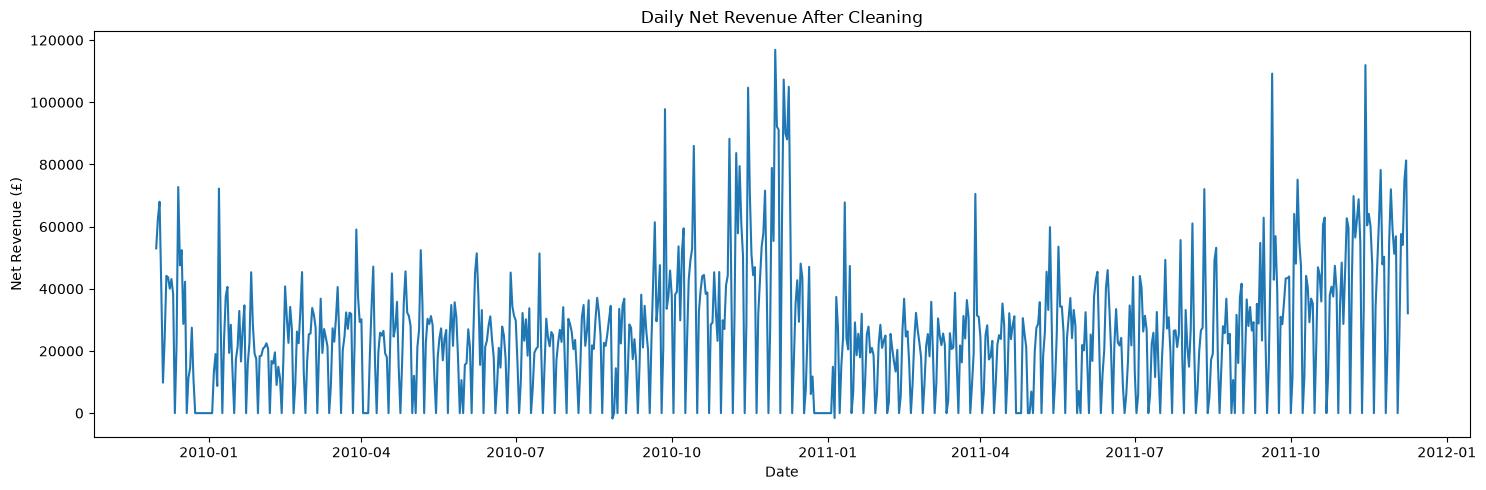

In [16]:
# Revenue Plot
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    daily_revenue["date"],
    daily_revenue["net_revenue"],
)

plt.title(
    "Daily Net Revenue After Cleaning"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Net Revenue (£)"
)

plt.tight_layout()

plt.show()

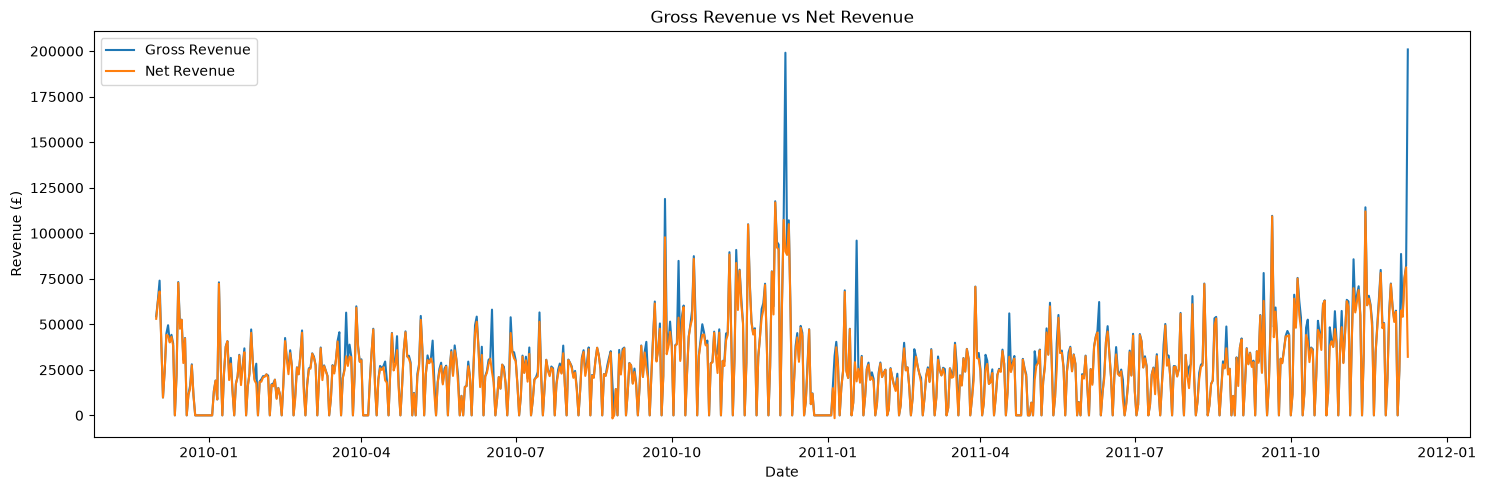

In [17]:
# Gross vs Net Revenue
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    daily_revenue["date"],
    daily_revenue["gross_revenue"],
    label="Gross Revenue",
)

plt.plot(
    daily_revenue["date"],
    daily_revenue["net_revenue"],
    label="Net Revenue",
)

plt.title(
    "Gross Revenue vs Net Revenue"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Revenue (£)"
)

plt.legend()

plt.tight_layout()

plt.show()

In [18]:
# Return Rate
daily_revenue[
    "return_rate"
].describe()

count    739.000000
mean       0.045341
std        0.105231
min        0.000000
25%        0.002300
50%        0.012261
75%        0.039587
max        1.095298
Name: return_rate, dtype: float64

In [19]:
average_return_rate = (
    daily_revenue[
        "return_rate"
    ].mean()
)

print(
    f"Average daily return rate: "
    f"{average_return_rate:.2%}"
)

Average daily return rate: 4.53%


In [20]:
# Cleaning Summary
summary = pd.DataFrame({
    "Metric": [
        "Raw rows",
        "Clean rows",
        "Valid sales",
        "Returns / cancellations",
        "Invalid transactions",
        "Daily observations",
    ],

    "Value": [
        len(raw_df),
        len(clean_df),
        len(valid_sales),
        len(returns_df),
        len(invalid_df),
        len(daily_revenue),
    ],
})

summary

,Metric,Value
0,Raw rows,1067371
1,Clean rows,1055238
2,Valid sales,1029609
3,Returns / cancellations,19433
4,Invalid transactions,6196
5,Daily observations,739


In [22]:
save_processed_data(
    result
)

print(
    "Processed datasets saved successfully."
)

Processed datasets saved successfully.


In [23]:
# re-read daily_revenue.csv
from ml.config import (
    DAILY_REVENUE_FILE,
)

check_df = pd.read_csv(
    DAILY_REVENUE_FILE,
    parse_dates=["date"],
)

check_df.head()

,date,gross_revenue,transaction_lines,invoices,return_revenue,return_lines,net_revenue,return_rate,year,month,day_of_week,is_weekend
0,2009-12-01,54351.23,3068.0,119.0,-1340.47,110.0,53010.76,0.024663,2009,12,1,0
1,2009-12-02,63172.58,3208.0,115.0,-588.92,20.0,62583.66,0.009322,2009,12,2,0
2,2009-12-03,73972.45,2931.0,124.0,-5944.86,44.0,68027.59,0.080366,2009,12,3,0
3,2009-12-04,40582.32,2479.0,89.0,-386.52,27.0,40195.80,0.009524,2009,12,4,0
4,2009-12-05,9803.05,400.0,30.0,0.00,0.0,9803.05,0.000000,2009,12,5,1


In [24]:
check_df.shape

(739, 12)